# 2. Construcción de los conjuntos y análisis exploratorio (EDA)

Primero se arman las tres tablas de modelado a partir de los datos extraídos (código visible y
editable); después, el EDA de la sección 9.10.4.1 del curso: análisis unidimensional, bidimensional,
faltantes y resumen ejecutivo.

- **P1** Kd por sector: tasa de crédito comercial nuevo por división CIIU, 4 tamaños a la vez, un mes adelante.
- **P2** Estructura de capital: D/E, cobertura, Kd contable y ROA del año siguiente de cada empresa con deuda.
- **P3** Insumos de mercado: spread soberano, TES pesos y UVR, inflación implícita, tasa de política y Tesoro.

In [1]:
import sys, warnings, json, time
from pathlib import Path
ML = Path.cwd().parent                      # carpeta ml/
sys.path.insert(0, str(ML))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
PROCESSED, REPORTS = ML / "data" / "processed", ML / "reports"
PRED = REPORTS / "predicciones"; PRED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")

In [2]:
# ===================== CONFIGURACIÓN =====================
P1_MONTO_MINIMO = 1e10          # pesos; celdas sector-tamaño-mes con menos crédito se tratan como faltantes
P2_ACTIVOS_MINIMOS = 500_000    # miles de pesos
P3_DESDE = "2016-01-31"
TAMANOS = ["Gran empresa", "Mediana empresa", "Pequeña empresa", "Microempresa"]
P3_OBJETIVOS = ["spread_soberano", "tes_cop_10a", "tes_uvr_10a", "inflacion_implicita_10a", "tasa_politica", "ust_10a"]

In [3]:
def macro_mensual():
    br, fr = pd.read_parquet(PROCESSED / "banrep_series.parquet"), pd.read_parquet(PROCESSED / "fred_series.parquet")
    def m(df, key, col, name):
        return df[df[key] == col].set_index("fecha")["valor"].sort_index().resample("ME").last().rename(name)
    out = pd.concat([m(br, "nombre", "Tasa de política", "tasa_politica"), m(br, "nombre", "IBR 3 meses", "ibr_3m"),
                     m(br, "nombre", "TES 1 año", "tes_1a_banrep"), m(br, "nombre", "TES 10 años", "tes_10a_banrep"),
                     m(br, "nombre", "TRM", "trm"), m(br, "nombre", "COLCAP", "colcap"),
                     m(fr, "serie", "DGS10", "ust_10a"), m(fr, "serie", "T10YIE", "bei_usd_10a")], axis=1)
    out.index = out.index + pd.offsets.MonthEnd(0)
    return out
MAC = macro_mensual(); MAC.tail(3)

,tasa_politica,ibr_3m,tes_1a_banrep,tes_10a_banrep,trm,colcap,ust_10a,bei_usd_10a
fecha,,,,,,,,
2026-08-31,12.00,11.420,12.274713,12.842039,3202.79,2436.94,4.75,2.31
2026-09-30,12.00,11.557,12.336908,13.201798,3341.23,2560.61,5.29,2.36
2026-10-31,12.25,11.735,NaN,NaN,3238.88,NaN,5.27,2.36


## 2.1 Construcción de P1

In [4]:
# P1 · tasa ponderada por monto por (mes, división CIIU, tamaño); objetivo = las 4 tasas del mes siguiente
t = pd.read_parquet(PROCESSED / "superfinanciera_tasas_detalle.parquet")
t = t[t["modalidad"] != "Comercial tesoreria"]
g = t.assign(tm=t["tasa_ea"] * t["monto"]).groupby(["mes", "ciiu_division", "tamano"], as_index=False)[["tm", "monto"]].sum()
g["tasa"] = g["tm"] / g["monto"]; g.loc[g["monto"] < P1_MONTO_MINIMO, "tasa"] = np.nan
w = g.pivot_table(index=["ciiu_division", "mes"], columns="tamano", values="tasa").reindex(columns=TAMANOS)
w.columns = [f"tasa_{c.split()[0].lower()}" for c in w.columns]
w = w.join(g.groupby(["ciiu_division", "mes"])["monto"].sum().rename("monto_total")).reset_index().sort_values(["ciiu_division", "mes"])
TCOLS = [c for c in w.columns if c.startswith("tasa_")]
partes = []
for div, gg in w.groupby("ciiu_division"):
    gg = gg.set_index("mes"); f = pd.DataFrame(index=gg.index)
    for c in TCOLS:
        for k in (0, 1, 2): f[f"{c}_l{k}"] = gg[c].shift(k)        # rezagos 0, 1 y 2 meses
        f[f"y_{c}"] = gg[c].shift(-1)                               # objetivo: mes siguiente
    f["log_monto"] = np.log(gg["monto_total"]); f["ciiu_division"] = div
    partes.append(f.reset_index())
P1 = pd.concat(partes, ignore_index=True)
macm = MAC.copy(); macm.index = macm.index.to_period("M").to_timestamp()
P1 = P1.merge(macm[["tasa_politica", "ibr_3m", "tes_1a_banrep", "tes_10a_banrep"]], left_on="mes", right_index=True, how="left")
P1["mes_del_anio"] = P1["mes"].dt.month
P1_Y = [f"y_{c}" for c in TCOLS]
P1 = P1.dropna(subset=P1_Y)
P1["id"] = P1["ciiu_division"] + "_" + P1["mes"].dt.strftime("%Y-%m")
P1.to_parquet(PROCESSED / "dataset_p1.parquet", index=False)
print(P1.shape, "| divisiones:", P1.ciiu_division.nunique(), "| meses:", P1.mes.nunique())

(691, 25) | divisiones: 47 | meses: 48


## 2.2 Construcción de P2

In [5]:
# P2 · empresas con deuda en t y t+1; objetivos del año siguiente: D/E, cobertura, Kd contable y ROA
p = pd.read_parquet(PROCESSED / "supersociedades_panel_2016_2025.parquet")
p = p[(p["activos"] >= P2_ACTIVOS_MINIMOS) & (p["patrimonio"] > 0)].copy()
p = p.assign(roa=p["ebit"] / p["activos"], cob=p["cobertura_intereses"], kd=p["kd_implicito"], de=p["d_e_contable"])
keep = ["nit", "anio", "ciiu_division", "activos", "ingresos", "deuda", "efectivo", "de", "cob", "kd", "roa", "tasa_impuesto_efectiva", "deuda_ant"]
p = p[keep]
nxt = p[["nit", "anio", "de", "cob", "kd", "roa"]].assign(anio=lambda d: d["anio"] - 1)
nxt.columns = ["nit", "anio", "y_de", "y_cob", "y_kd", "y_roa"]
prev = p[["nit", "anio", "de", "roa"]].assign(anio=lambda d: d["anio"] + 1).rename(columns={"de": "de_l1", "roa": "roa_l1"})
d = p.merge(nxt, on=["nit", "anio"]).merge(prev, on=["nit", "anio"], how="left")
# Acotar errores de registro (en entradas y objetivos) y transformar escalas muy sesgadas
d["y_de"] = np.log1p(d["y_de"].clip(0, 20)); d["y_cob"] = np.arcsinh(d["y_cob"].fillna(0).clip(-50, 50))
d["y_kd"] = d["y_kd"].where(d["y_kd"].between(0.0, 0.6)); d["y_roa"] = d["y_roa"].clip(-1, 1)
d["kd"] = d["kd"].where(d["kd"].between(0.0, 0.6)); d["roa"] = d["roa"].clip(-1, 1); d["roa_l1"] = d["roa_l1"].clip(-1, 1)
d["de"] = np.log1p(d["de"].clip(0, 20)); d["de_l1"] = np.log1p(d["de_l1"].clip(0, 20)); d["cob"] = np.arcsinh(d["cob"].fillna(0).clip(-50, 50))
dic = MAC[MAC.index.month == 12].copy(); dic.index = dic.index.year
d = d.merge(dic[["tasa_politica", "tes_10a_banrep", "ust_10a"]], left_on="anio", right_index=True, how="left")
d["log_activos"] = np.log(d["activos"]); d["margen"] = (d["roa"] * d["activos"] / d["ingresos"].replace(0, np.nan)).clip(-2, 2)
d["caja_activos"] = d["efectivo"].fillna(0) / d["activos"]; d["deuda_activos"] = d["deuda"] / d["activos"]
d["crec_deuda"] = (d["deuda"] / d["deuda_ant"].replace(0, np.nan) - 1).clip(-1, 5)
d = d[d["y_kd"].notna() & (d["deuda"] > 0) & d["y_roa"].notna()]
d["ciiu_division"] = d["ciiu_division"].fillna("NA"); d["anio_objetivo"] = d["anio"] + 1
d["id"] = d["nit"].astype(str) + "_" + d["anio_objetivo"].astype(str)
P2_Y = ["y_de", "y_cob", "y_kd", "y_roa"]
P2 = d; P2.to_parquet(PROCESSED / "dataset_p2.parquet", index=False)
print(P2.shape, "| empresas:", P2.nit.nunique(), "| años objetivo:", sorted(P2.anio_objetivo.unique()))

(65739, 29) | empresas: 18517 | años objetivo: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## 2.3 Construcción de P3

In [6]:
# P3 · series mensuales de mercado
be = pd.read_csv(REPORTS / "inflacion_implicita_mensual.csv", parse_dates=["fecha"]).set_index("fecha")
sp = pd.read_csv(REPORTS / "spread_soberano_mensual.csv", parse_dates=["fecha"]).set_index("fecha")
P3 = pd.concat([sp["spread_soberano_10a_pp"].rename("spread_soberano"), be[["tes_cop_10a", "tes_uvr_10a", "inflacion_implicita_10a"]]], axis=1)
P3.index = P3.index + pd.offsets.MonthEnd(0)
P3 = P3.join(MAC[["tasa_politica", "ust_10a", "ibr_3m", "trm", "colcap", "bei_usd_10a"]]).loc[P3_DESDE:].sort_index()
P3["imputado"] = P3[P3_OBJETIVOS].isna().any(axis=1)
P3[P3_OBJETIVOS] = P3[P3_OBJETIVOS].interpolate(limit_direction="both")
P3.to_parquet(PROCESSED / "dataset_p3.parquet")
print(P3.shape, P3.index.min().date(), "→", P3.index.max().date(), "| meses imputados:", int(P3.imputado.sum()))

(127, 11)

 2016-01-31 → 2026-07-31 | meses imputados: 5


## 2.4 EDA · P1

In [7]:
from scipy import stats
def univariado(df):
    num = df.select_dtypes("number"); q1, q3 = num.quantile(0.25), num.quantile(0.75); iqr = q3 - q1
    return pd.DataFrame({"media": num.mean(), "mediana": num.median(), "desv": num.std(), "min": num.min(), "p25": q1,
                         "p75": q3, "max": num.max(), "IQR": iqr,
                         "%_atipicos_IQR": ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean() * 100,
                         "asimetria": num.skew(), "%_faltantes": num.isna().mean() * 100}).round(3)

In [8]:
univariado(P1[P1_Y])

,media,mediana,desv,min,p25,p75,max,IQR,%_atipicos_IQR,asimetria,%_faltantes
y_tasa_gran,15.542,14.833,3.870,2.531,13.182,17.546,33.450,4.364,3.618,0.700,0.0
y_tasa_mediana,16.655,16.123,3.272,8.539,14.361,18.192,34.647,3.830,3.039,1.218,0.0
y_tasa_pequeña,17.956,17.503,3.278,10.001,15.876,19.982,32.495,4.107,1.013,0.498,0.0
y_tasa_microempresa,16.914,16.671,4.052,1.093,14.666,19.107,30.125,4.441,2.460,0.085,0.0


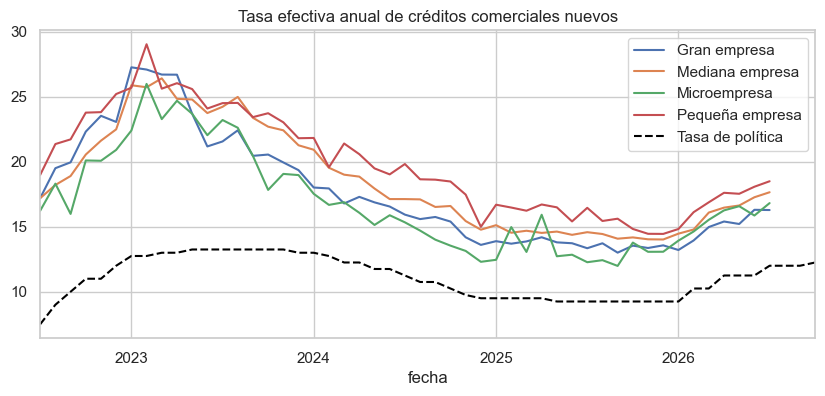

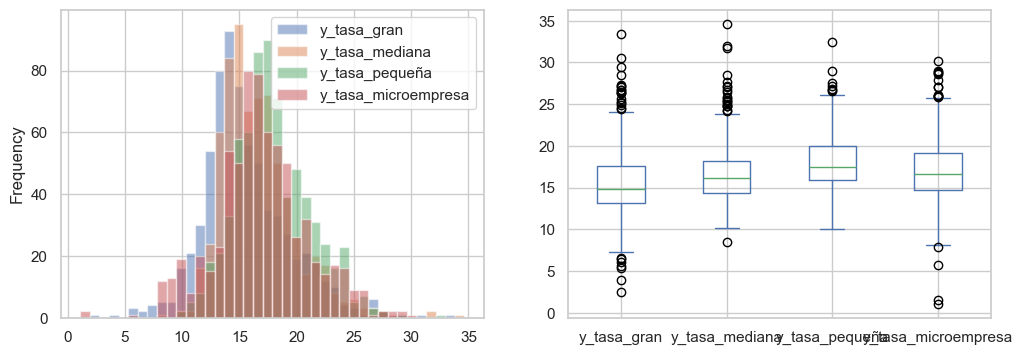

Shapiro-Wilk p: {'y_tasa_gran': 0.0, 'y_tasa_mediana': 0.0, 'y_tasa_pequeña': 0.0, 'y_tasa_microempresa': 0.0}


In [9]:
s = t.assign(tm=t.tasa_ea * t.monto).groupby(["mes", "tamano"])[["tm", "monto"]].sum(); s = (s.tm / s.monto).unstack()
ax = s.plot(figsize=(10, 4), title="Tasa efectiva anual de créditos comerciales nuevos")
macm.loc[s.index.min():, "tasa_politica"].plot(ax=ax, color="black", ls="--", label="Tasa de política"); ax.legend(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); P1[P1_Y].plot(kind="hist", bins=40, alpha=.5, ax=ax[0]); P1[P1_Y].plot(kind="box", ax=ax[1]); plt.show()
print("Shapiro-Wilk p:", {c: round(stats.shapiro(P1[c])[1], 4) for c in P1_Y})

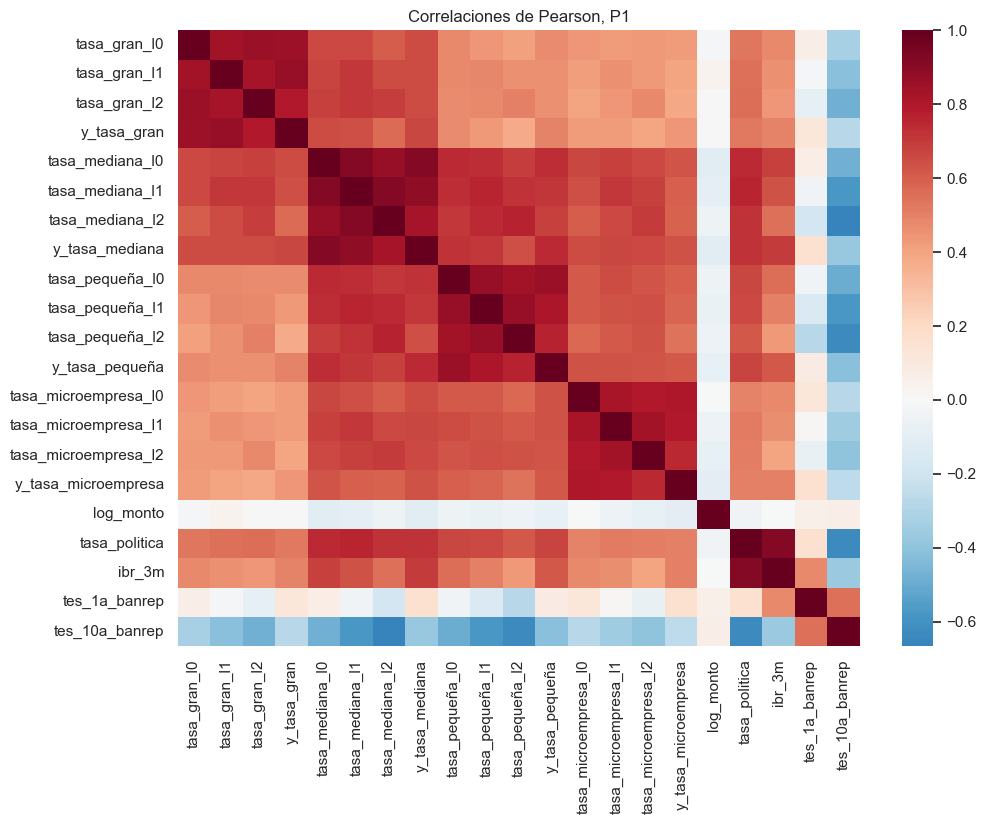

,y_tasa_gran,y_tasa_mediana,y_tasa_pequeña,y_tasa_microempresa
tasa_gran_l1,0.87,0.65,0.46,0.40
tasa_gran_l0,0.85,0.65,0.47,0.43
tasa_gran_l2,0.80,0.65,0.45,0.39
tasa_mediana_l0,0.65,0.91,0.73,0.62
tasa_mediana_l1,0.65,0.89,0.71,0.60
tasa_mediana_l2,0.57,0.83,0.67,0.59
tasa_politica,0.53,0.72,0.67,0.50
ibr_3m,0.50,0.70,0.62,0.50
tasa_pequeña_l0,0.47,0.72,0.86,0.60
tasa_pequeña_l1,0.43,0.71,0.81,0.58


In [10]:
num1 = P1.select_dtypes("number").drop(columns=["mes_del_anio"])
plt.figure(figsize=(11, 8)); sns.heatmap(num1.corr(), cmap="RdBu_r", center=0); plt.title("Correlaciones de Pearson, P1"); plt.show()
num1.corr()[P1_Y].drop(P1_Y).round(2).sort_values("y_tasa_gran", ascending=False).head(10)

## 2.5 EDA · P2

In [11]:
univariado(P2[P2_Y + ['log_activos','de','de_l1','cob','kd','roa','margen','caja_activos','crec_deuda']])

,media,mediana,desv,min,p25,p75,max,IQR,%_atipicos_IQR,asimetria,%_faltantes
y_de,0.469,0.310,0.527,0.000,0.106,0.642,3.045,0.536,5.380,2.247,0.000
y_cob,1.528,1.602,1.759,-4.605,0.897,2.529,4.605,1.632,6.003,-0.927,0.000
y_kd,0.177,0.150,0.139,0.000,0.074,0.250,0.600,0.176,2.969,0.905,0.000
y_roa,0.081,0.067,0.108,-1.000,0.022,0.127,1.000,0.106,4.900,0.007,0.000
log_activos,16.731,16.560,1.409,13.133,15.751,17.546,24.291,1.795,1.923,0.700,0.000
de,0.485,0.330,0.524,0.000,0.123,0.663,3.045,0.541,5.102,2.215,0.000
de_l1,0.457,0.311,0.508,0.000,0.097,0.643,3.045,0.545,3.668,2.193,20.163
cob,1.455,1.505,1.655,-4.605,0.689,2.405,4.605,1.716,4.177,-0.743,0.000
kd,0.167,0.142,0.128,0.000,0.076,0.231,0.600,0.155,3.149,0.998,13.274
roa,0.082,0.067,0.105,-1.000,0.023,0.127,1.000,0.104,4.813,0.362,0.003


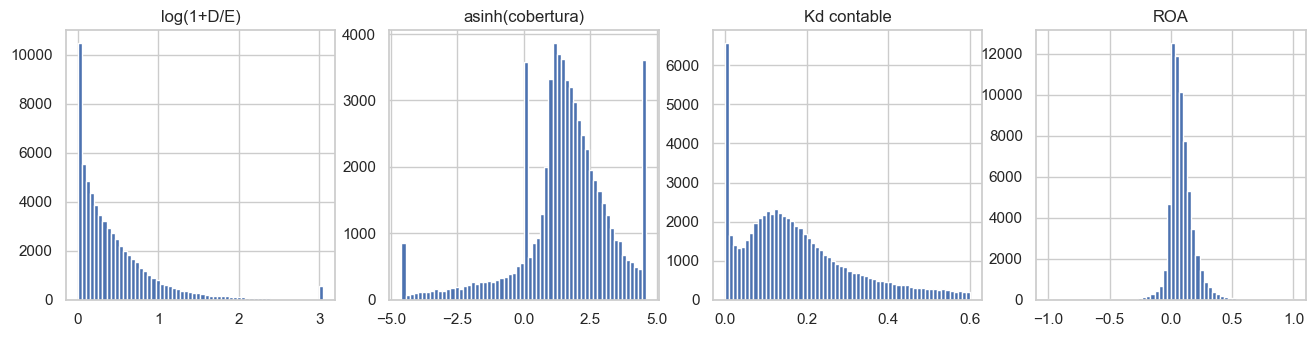

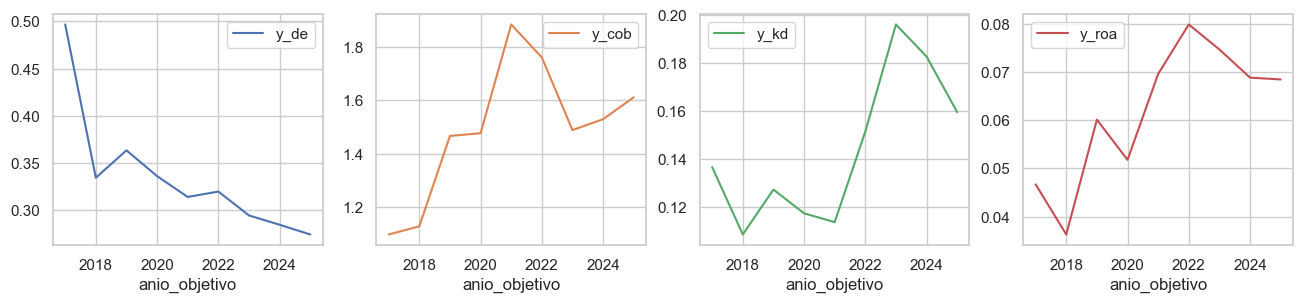

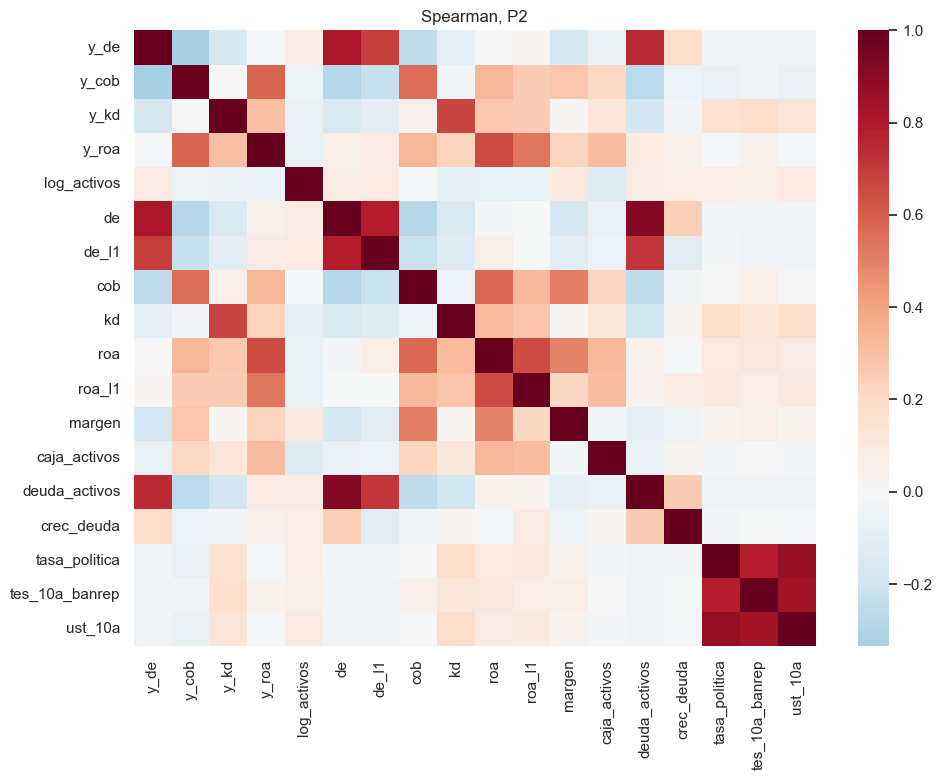

y_de            de                0.82
de              de_l1             0.80
tasa_politica   tes_10a_banrep    0.83
                ust_10a           0.90
tes_10a_banrep  ust_10a           0.87
dtype: float64
Faltantes (%):
de_l1         20.2
kd            13.3
roa_l1        20.2
margen         2.0
crec_deuda     4.3
dtype: float64


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c, lab in zip(axes, P2_Y, ["log(1+D/E)", "asinh(cobertura)", "Kd contable", "ROA"]): a.hist(P2[c], bins=60); a.set_title(lab)
plt.show(); P2.groupby("anio_objetivo")[P2_Y].median().plot(subplots=True, layout=(1, 4), figsize=(16, 3)); plt.show()
num2 = P2[P2_Y + ["log_activos", "de", "de_l1", "cob", "kd", "roa", "roa_l1", "margen", "caja_activos", "deuda_activos", "crec_deuda", "tasa_politica", "tes_10a_banrep", "ust_10a"]]
plt.figure(figsize=(11, 8)); sns.heatmap(num2.corr(method="spearman"), cmap="RdBu_r", center=0); plt.title("Spearman, P2"); plt.show()
alta = num2.corr().abs().where(lambda m: np.triu(np.ones(m.shape), 1).astype(bool)).stack(); print(alta[alta > .7].round(2))
print("Faltantes (%):"); print(num2.isna().mean().mul(100).round(1)[lambda s: s > 0])

## 2.6 EDA · P3

In [13]:
univariado(P3[P3_OBJETIVOS])

,media,mediana,desv,min,p25,p75,max,IQR,%_atipicos_IQR,asimetria,%_faltantes
spread_soberano,2.699,2.643,0.917,1.189,1.809,3.305,4.953,1.496,0.0,0.410,0.0
tes_cop_10a,8.865,7.638,2.557,5.451,6.682,11.526,13.784,4.844,0.0,0.394,0.0
tes_uvr_10a,4.162,3.587,1.327,2.004,3.222,5.204,7.134,1.982,0.0,0.526,0.0
inflacion_implicita_10a,4.502,4.004,1.213,2.856,3.394,5.619,7.218,2.225,0.0,0.400,0.0
tasa_politica,6.990,6.250,3.672,1.750,4.250,9.875,13.250,5.625,0.0,0.262,0.0
ust_10a,2.779,2.690,1.218,0.550,1.760,4.005,4.880,2.245,0.0,-0.013,0.0


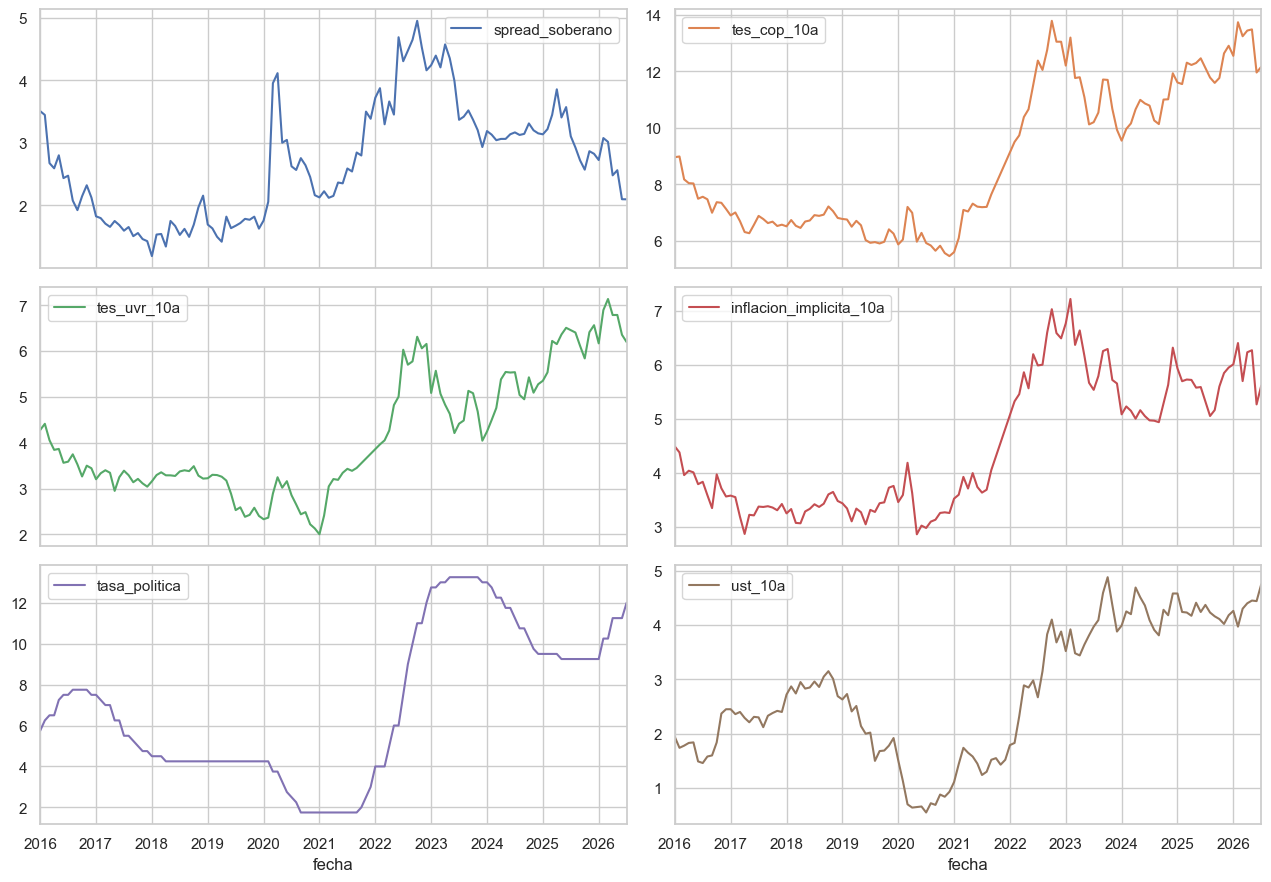

,ADF nivel (p),ADF diferencia (p)
spread_soberano,0.2512,0.0000
tes_cop_10a,0.8555,0.0000
tes_uvr_10a,0.8255,0.0000
inflacion_implicita_10a,0.6497,0.0000
tasa_politica,0.3721,0.1658
ust_10a,0.8680,0.0000


In [14]:
from statsmodels.tsa.stattools import adfuller
P3[P3_OBJETIVOS].plot(subplots=True, layout=(3, 2), figsize=(13, 9), sharex=True); plt.tight_layout(); plt.show()
pd.DataFrame({c: {"ADF nivel (p)": adfuller(P3[c])[1], "ADF diferencia (p)": adfuller(P3[c].diff().dropna())[1]} for c in P3_OBJETIVOS}).T.round(4)

## 2.7 Resumen ejecutivo del EDA (corrida del 9 de octubre de 2026)

- **Calidad.** P1: 691 sector-meses (47 divisiones, 48 meses) sin faltantes en los objetivos. P2:
  65.739 empresas-año con deuda (18.517 empresas); las entradas tenían errores de registro extremos
  (Kd contable de 49.101, ROA de −326) y se acotan como los objetivos. P3: 127 meses, 5 imputados.
- **Persistencia.** La tasa del mes siguiente se correlaciona 0,85–0,91 con la actual; el D/E del año
  siguiente, 0,82 con el actual. La persistencia es la línea base exigente.
- **Distribuciones.** No normales (Shapiro-Wilk p < 0,001). Pequeña empresa paga la tasa más alta
  (mediana 17,5 %) y gran empresa la más baja (14,8 %).
- **Estacionariedad (P3).** Series no estacionarias en niveles y estacionarias en diferencias (ADF):
  paseo aleatorio como línea base y VAR en diferencias.
- **Problemas.** Multicolinealidad tasa de política–TES–Tesoro (|r| 0,83–0,90); 20 % de faltantes en
  rezagos y 19 % en la tasa efectiva. Se tratan dentro del pipeline (imputación por mediana) y con
  regularización (Ridge, Lasso).